## Learning without examples

When we want to learn from data without knowing the labels, we apply unsupervised learning: different techniques to make sense of data from the data itself.  Assignment 7 you will practice with k-means clustering and implement PCA to reduce dimensionality of data.

## K-means clustering

As a child you probably taught yourself how to separate building blocks from each other. Even without someone telling you which shape was which, you were able to decide which shapes belonged with each other and make separate heaps of cubes, cylinders, and pyramids. You performed a type of unsupervised learning: *clustering*.

## 1. Preparing the data

We will work with the *TIDIGITS* dataset. This dataset was created by Texas Instruments (hence, TI) and is a set of voice recordings of digits. 

Before we can use any clustering algorithms on this data, we need a way to describe our audio files in a way that a computer can understand. An audio file is read as an array, where each value in the array is the amplitude of the audio at a the corresponding time. We refer to this data as _raw_ waveforms. It's infeasible to use the raw data for clustering. We need to extract a limited number of features to describe each audiofile: we perform __feature extraction__.

From the audiofiles we extracted _MFCC_ features, which are often used for speech processing. We split the audio file in frames of 25 ms each and applied a number of complicated operations to retrieve 13 features per frame. If a file is split into, for example, 100 frames, this means we have $13 * 100 = 1300$ features! To bring this number down, we further sampled  5  frames from regular intervals (the size of the interval is dependent on the length of the audio file) and flattened this to an array of  $5 ∗ 13 = 65$  features (this number is thus independent of the length of the audio file).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

X_train = np.loadtxt("data/tidigits_features.txt")
y_train = np.loadtxt("data/tidigits_targets.txt")

### Reducing the number of features

Now we have 150 data points (i.e. 150 audio files) and each data point consists of 65 features describing the audio file. Let's plot the the first two features.

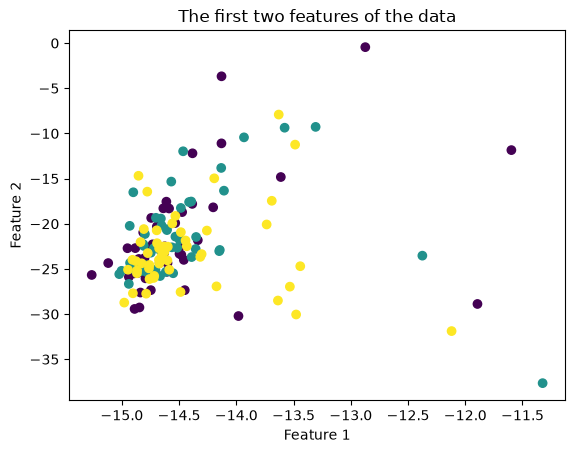

In [4]:
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train)
plt.title('The first two features of the data')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.show()

Well, it seems like we can't cluster our points based on the first two features. There is however some combination of features that will allow us to cluster the data points. If only there was a way to automatically find this combination without supervision...

But wait! We do have such a technique: PCA. We will find the four most descriptive 'directions' in the data and project the features onto these directions.

This involves the following steps:
1. compute the covariance matrix of the dataset;
2. compute the first four eigenvectors (i.e. principal components) of the covariance matrix;
3. reorient the data points from the original axes to the ones represented by these principal components (this is done using the dot product).
   
This should give us four features for each point that describe the audio well. We are plotting just two of these features, as this can be easily visualised, but we will need four features to accurately cluster all points.

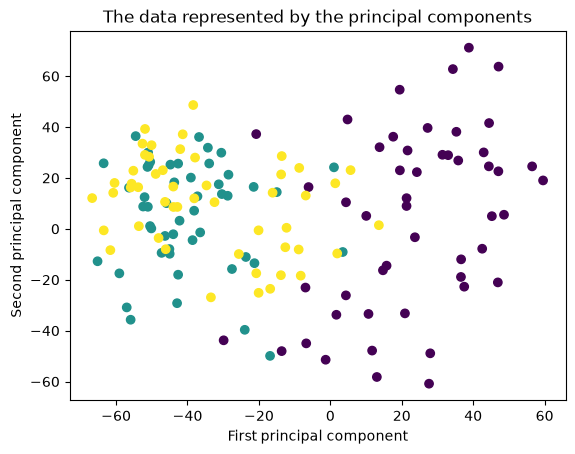

In [6]:
# First compute the covariance matrix of the dataset

X = X_train   

X_centered = X - np.mean(X, axis=0)

N = len(X_centered)

cov_matrix = 1/N * np.dot(X_centered.T, X_centered)

# Next, retrieve four eigenvectors of the covariance matrix using np.linalg.eig()
eigenvalues, eigenvectors_total = np.linalg.eig(cov_matrix)

pairs = [] 

for i in range(len(eigenvalues)): 
    pairs.append((eigenvalues[i], eigenvectors_total[:, i]))


pairs.sort(key=lambda x: x[0], reverse=True)


count = 0 

eigenvectors = np.zeros((X_train.shape[1], 4))

for i in range(len(pairs)):
    if count < 4:
        eigenvectors[:, count] = pairs[i][1]
        count += 1

# Finally, we project our points onto the eigenvectors (principal components) using matrix multiplication
X_train_reduced = np.zeros((X_train.shape[0], 4))
for i in range(len(X_train)):
    X_train_reduced[i, :] = np.matmul(X_train[i, :].T, eigenvectors).T
        
# And plot the points with the new data
plt.scatter(X_train_reduced[:, 0], X_train_reduced[:, 1], c=y_train)
plt.title('The data represented by the principal components')
plt.xlabel('First principal component')
plt.ylabel('Second principal component')
plt.show()

Looks like we have ourselves a dataset that we can start clustering!

# 2. K-means clustering

We will now implement the (original) k-means clustering algorithm. This algorithm works as follows: we start with $k$ clusters and pick some random centre (mean) for each cluster. Next, we assign points to each cluster based on the distance to the centres and we update the centre to be the mean of all points in that cluster. This is repeated until the centres have converged.

Pointwise, the steps of the k-means clustering algorithm approach are as follows:
1. initialize $k$ cluster centers at random locations;
2. assign each point to a cluster;
3. update the cluster centers;
4. go to step 2 unless converged or a certain number of iterations has been reached.

First, we will create a `Cluster` class.

In [7]:
import numpy as np

# This object is used to store the clusters. A Cluster object consists of a numpy matrix
# containing all feature vectors in the cluster and the centroid of all the vectors.
# The object also contains a boolean for speedup purposes.
class Cluster(object):

    def __init__(self, array=np.array([])):
        self.changed = True
        self.data = np.array(array)
        self.cd = self.data
        
    def reset_cluster(self):
        self.data = np.array([])
    
    def is_changed(self):
        return self.changed
    
    def set_changed(self, changed):
        self.changed = changed
    
    def set_centroid(self, vector):
        self.cd = vector
    
    def append(self, other):
        # Set changed flag to true (the cluster has changed)
        self.set_changed(True)
        
        self.data = np.vstack((self.data, other))

    def centroid(self):
        # If the matrix consists of 1 vector, no need to compute centroid.
        if len(np.shape(self.data)) == 1:
            return self.data

        if self.is_changed(): 
            self.cd = np.mean(self.data, axis=0) 
            self.set_changed(False) 
        
        return self.cd
    
# Test case for the Cluster class
c = Cluster(np.array([[0, 1], [2, 0]]))

# Verifies that the centroid is calculated correctly
np.testing.assert_array_equal(c.centroid(), np.array([1.0, 0.5]))

# Verifies that the centroid is calculated correctly after a new data point has been added.
c.append(np.array([1, 2]))
np.testing.assert_array_equal(c.centroid(), np.array([1.0, 1.0]))

Next, let's take a look at the data that we will be clustering. We plotted the data here as the algorithm will see it, thus without labels.

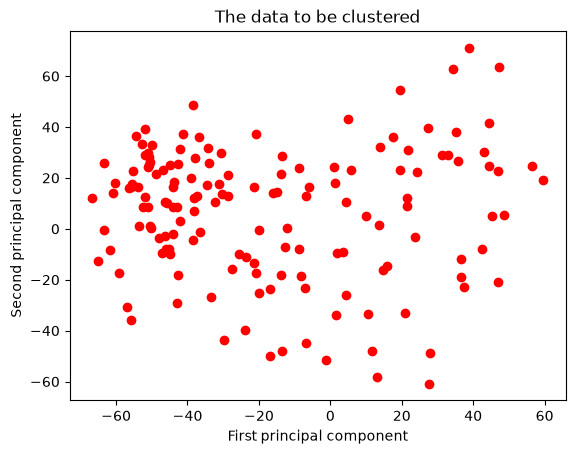

In [8]:
import matplotlib.pyplot as plt
%matplotlib inline

# This function is only used when the previous steps for feature extraction and reduction have failed.
# It can be used to load the given cluster data into a list of cluster objects.
def read_file(file):
    lines = [line.rstrip('\n') for line in open(file)]
    # Initialise data structure
    points = []
    for line in lines:
        # Take FeatureVector from dataset
        elements = line.split(" ")
        p = [float(el) for el in elements]
        # Append FeatureVector to the list of clusters
        points.append(p)
    points = np.asarray(points)
    return points

# If the previous steps for feature extraction and reduction failed, you can use this data.
# Otherwise, use the data and features you extracted yourself!

# points = read_file("data/cluster.txt")

points = X_train_reduced
x = points[:, 0]
y = points[:, 1]
plt.scatter(x, y, c='r')
plt.title('The data to be clustered')
plt.xlabel('First principal component')
plt.ylabel('Second principal component')
plt.show()

### Step 1

Now you will start implementing k-means. Let's work on step 1: *initialize $k$ cluster centers at random locations*.

 This function selects a random point in the dataset, constructs a cluster from it and adds the cluster to the list of clusters.  

In [16]:
from random import sample

# This function selects random k points from the dataset. For each random point it initializes a cluster 
# and adds the cluster to the list of clusters.
def add_init_points(points, clusters, k):

    random_point = sample(list(points), k)

    for point in random_point:
        clusters.append(Cluster(point))
    
    return clusters

# Verifies that a cluster has been added as a init point
init_points = add_init_points(np.array([[0, 0], [0, 0]]), [], 1)
assert len(init_points) == 1
np.testing.assert_array_equal(init_points[0].centroid(), np.array([0.0, 0.0]))

### Step 2
In the update process, we assign points to clusters based on their distance to each centroid. This is step 2 of k-means: *assign each point to a cluster*.

In [17]:
def distance(p1, p2):
    # Euclidian distance between 2 points (in any space)
    return np.linalg.norm(p1 - p2)

# Verifies that the distance metric is correct
np.testing.assert_array_equal(distance(np.zeros([1, 2]), np.ones([1, 2])), np.sqrt(2))

### Step 3
 Now implement the update step (3.) of the k-means clustering algorithm. First, use `addInitPoint` if no clusters are present yet to initialize $k$ clusters. After this check, we perform an iteration of the k-means clustering algorithm. This consists of the following steps: 


You will want to save the cluster centroids as they will change during the last step when they are recalculated.

In [18]:
import sys

# This function updates the list of k clusters
def update_k_means(points, clusters, k):
    # Reset clusters
    centroids = []

    for cluster in clusters:
        centroids.append(cluster.centroid().copy())
        cluster.reset_cluster()

    for point in points:
        minn = sys.maxsize

        for i, cluster in enumerate(clusters):
            if minn > distance(point, centroids[i]):
                minn = distance(point, centroids[i])
                closest_cluster = cluster

        if closest_cluster.data.size == 0:
            closest_cluster.data = np.array(point)
            closest_cluster.set_changed(True)
        else:
            closest_cluster.append(point)

    updated_clusters = []

    for cluster in clusters:
        updated_clusters.append(cluster)

    return updated_clusters

In [19]:
import matplotlib.cm as cm
    
def plot_k_means_data( clusters, k, itr):
    colors = cm.brg(np.linspace(0,1,k))
    for (i,cl) in enumerate(colors):
        x = [[el[0]] for el in clusters[i].data]
        y = [[el[1]] for el in clusters[i].data] 
        plt.scatter(x, y, c=[cl])
        plt.scatter(clusters[i].centroid()[0], clusters[i].centroid()[1], c='black')
        plt.title("Clusters at update " + str(itr))
    plt.show()
    
def plot_k_means_data_update(clusters_prev, clusters, k):
    if(clusters_prev == []):
        return
    colors = cm.brg(np.linspace(0,1,k))
    for (i,cl) in enumerate(colors):
        
        x = [[el[0]] for el in clusters[i].data]
        y = [[el[1]] for el in clusters[i].data] 
        plt.scatter(x, y, c=[cl], marker = '*')

        plt.scatter(clusters[i].centroid()[0], clusters[i].centroid()[1], c='black')
        
        x_prev = [[el[0]] for el in clusters_prev[i].data]
        y_prev = [[el[1]] for el in clusters_prev[i].data]
        
        plt.scatter(x_prev, y_prev, c=[cl], alpha=0.2, s=100)
        
        plt.scatter(clusters_prev[i].centroid()[0], clusters_prev[i].centroid()[1], c='green')
        plt.legend(['New clusters', 'New centroids', 'Previous clusters', 'Previous centroids'], 
                   loc='center left', bbox_to_anchor=(1, 0.5))
        plt.title('Difference between updates')
    plt.show()

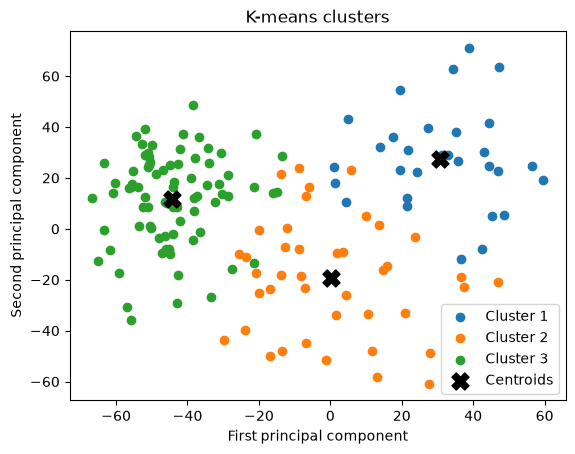

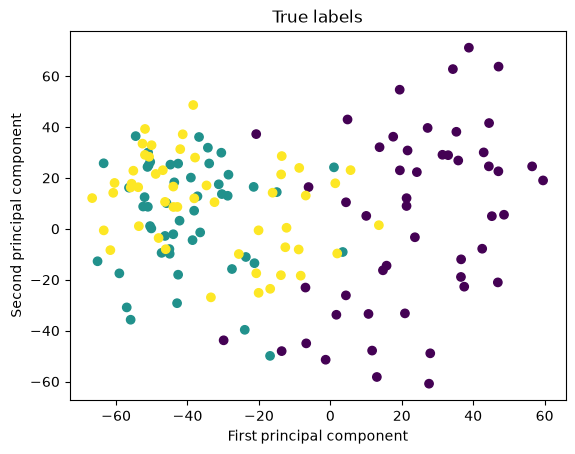

In [20]:
import copy
import random

random.seed(42)
points = X_train_reduced  # Ex 1.5a
# points = X_train       # Ex 1.5b (optional)
clusters = []
clusters_prev = []
centroids = []
k = 3
centroids_prev = [np.zeros(points.shape[1]) for x in range(k)]

add_init_points(points, clusters, k)

for iteration in range(10):
    centroids_prev = [cluster.centroid().copy() for cluster in clusters]

    clusters = update_k_means(points, clusters, k)

    centroids = []
    for cluster in clusters:
        if cluster.data.size == 0:
            centroid = cluster.cd
        else:
            centroid = cluster.centroid()

        centroids.append(centroid.copy())

    if np.allclose(centroids, centroids_prev):
        break

for i, cluster in enumerate(clusters):
    if cluster.data.size != 0:
        cluster_points = np.atleast_2d(cluster.data)
        plt.scatter(
            cluster_points[:, 0],
            cluster_points[:, 1],
            label=f'Cluster {i + 1}'
        )

centroids = np.array(centroids)
plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    c='black',
    marker='X',
    s=150,
    label='Centroids'
)

plt.title('K-means clusters')
plt.xlabel('First principal component')
plt.ylabel('Second principal component')
plt.legend()
plt.show()

plt.scatter(points[:, 0], points[:, 1], c=y_train)
plt.title('True labels')
plt.xlabel('First principal component')
plt.ylabel('Second principal component')
plt.show()

### Step 5

Now that we have a cluster, we would like to find out how good our clustering is. We will also do this using an unsupervised approach: without knowing the correct labels for each cluster, we _can_ say something about the spread of each cluster.

For this purpose you will compute the _sum of residual squares_ (SRS) of the cluster. This is computed as follows: sum over the squared euclidean distances between each point and their corresponding centroid and divide by the total number of points. In math notation:

$$
    srs = \frac{1}{N} \sum_{i \in C} (p_i - c)^2
$$

with $N$ the number of points, $C$ the cluster containing point $i$ and centroid $c$, and $p_i$ the feature vector for point $i$.

In [21]:
def calculate_average_sum_rs(cluster):
    if len(cluster.data) == 0:
        return None
    return np.mean(np.sum((cluster.data - cluster.centroid())**2, axis=1))

### Step 6

Next, we will use this metric to try and automatically determine how many clusters we should use.
 This method should test out several values for $k$ in range from 1 to 15. Then, for each $k$, run the k-means algorithm on `data/cluster.txt` with $10$ update iterations. After the algorithm is done, calculate the average SRS of all clusters and print them.

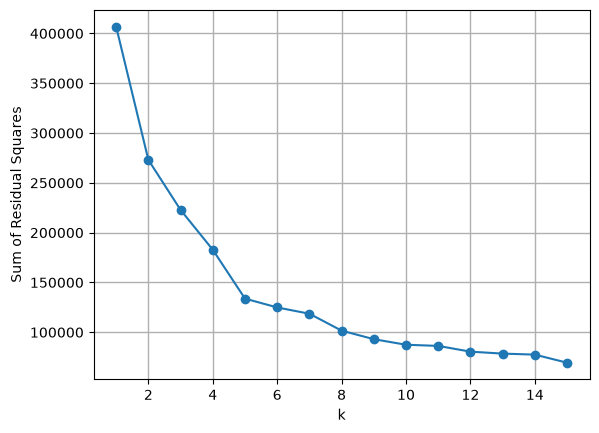

In [22]:
random.seed(42)

# This function tries a number of k's and calculates the SRS for each k.
# For each k, n_updates iterations are performed.
def tune_k(min_k, max_k, n_updates):
    assert 0 < min_k < max_k
    assert n_updates > 1
    srss = []

    # START ANSWER
    for k in range(min_k, max_k + 1):
        clusters = []
        add_init_points(points, clusters, k)

        for iteration in range(n_updates):
            clusters = update_k_means(points, clusters, k)

        srs = 0

        for cluster in clusters:
            if cluster.data.size != 0:
                average_rs = calculate_average_sum_rs(cluster)
                number_of_points = np.atleast_2d(cluster.data).shape[0]
                srs += average_rs * number_of_points

        srss.append(srs)
    # END ANSWER

    plt.plot(list(range(min_k, max_k + 1)), srss, marker='o')
    plt.xlabel('k')
    plt.ylabel('Sum of Residual Squares')
    plt.grid(linestyle='-', linewidth=1)
    plt.show()


min_k = 1
max_k = 15
n_updates = 10
tune_k(min_k, max_k, n_updates)

A good choice is k = 5, because the curve has an elbow around this value. Up to k = 5, adding clusters substantially reduces SRS. Beyond this value, the improvements are generally smaller ("elbow method")

The average SRS would be 0 if k equals to the numbers of data points because each point forms its own cluster, its centroid is the point itself. Therefore, every point has zero distance to its centroid